Ujian Tengah Semester Graf Sains Data

Implementasi Python Driver Neo4j dan Sistem Rekomendasi
Menggunakan Dataset RetailRocket

Ananta Putri Clara (24031554031)

In [1]:
import os
import getpass
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from tqdm import tqdm
from scipy.sparse import coo_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase
from IPython.display import display

print("Library berhasil diimpor.")

Library berhasil diimpor.


### 1. TUGAS PENDAHULUAN

In [ ]:
# Konfigurasi Koneksi
URI = "bolt://localhost:7687"
USER = "neo4j"

PASSWORD = os.getenv("********")

if not PASSWORD:
    PASSWORD = getpass.getpass("Password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Neo4j berhasil.")

C:\Users\Asus\AppData\Local\Temp\ipykernel_880\3022320233.py:15: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil.


In [8]:
# Graf Pertemanan

def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )


def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        records = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend
            ORDER BY friend
            """,
            name=name
        )

        for record in records:
            print(record["friend"])


add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


PERTANYAAN PENDAHULUAN

**1. Apa nama database yang digunakan?**

Database yang digunakan adalah neo4j, sesuai parameter database="neo4j".

**2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance.**

Untuk mengakses database lain dalam satu instance, dapat menggunakan perintah SHOW DATABASES untuk melihat daftar database dan :use nama_database pada Neo4j Query untuk berpindah database. Melalui Python Driver, database tujuan dapat ditentukan menggunakan parameter database pada session.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf yang dibuat merupakan graf berarah (directed graph), karena relationship KNOWS memiliki arah dari Arthur menuju Guinevere, Lancelot, dan Merlin.

1.3 Impor Data RetailRocket ke Database Neo4j

Dataset RetailRocket diimpor menggunakan mekanisme batch berukuran 10.000 baris. Node yang digunakan adalah Visitor dan Item, sedangkan jenis relationship meliputi VIEWED, ADDED_TO_CART, dan BOUGHT.

In [3]:
import os
import sys
import pandas as pd

from tqdm import tqdm
from neo4j import GraphDatabase

In [3]:
source = "dataset"

csv_file_path = os.path.join(source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")

File ditemukan: dataset\events.csv


In [ ]:

# Membuat constraint
def create_constraints(session):
    print("Membuat constraint & index unik untuk Visitor dan Item...")

    session.run("""
        CREATE CONSTRAINT visitor_id_uniq IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_uniq IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemid IS UNIQUE
    """)

    print("Constraint & index berhasil dibuat.")


# Fungsi query Cypher untuk impor per batch
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionid: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


# Main function
def main():
    neo4j_user = USER
    neo4j_password = PASSWORD
    neo4j_bolt = URI

    data_source = "dataset"

    # Cek file events.csv
    csv_file_path = os.path.join(data_source, "events.csv")

    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        return

    # Uji koneksi ke Neo4j
    try:
        driver = GraphDatabase.driver(
            neo4j_bolt,
            auth=(neo4j_user, neo4j_password)
        )
        driver.verify_connectivity()
        print("Berhasil terhubung ke database Neo4j.")

    except Exception as e:
        print(f"Gagal terhubung ke database: {e}")
        return

    # Impor per batch
    batch_size = 10000

    print(f"Membaca file data dari: {csv_file_path}")

    total_rows = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
    total_chunks = (total_rows + batch_size - 1) // batch_size

    print("Memulai proses impor data ke Neo4j...")

    with driver.session(database="neo4j") as session:
        create_constraints(session)

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size
        )

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor Batch Data"
        ):
            # Membersihkan data NULL/NaN
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            records = chunk.to_dict(orient="records")

            session.write_transaction(import_batch, records)

    driver.close()

    print("Proses impor berhasil selesai 100%!")


# main()

C:\Users\Asus\AppData\Local\Temp\ipykernel_51340\3741906111.py:77: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Berhasil terhubung ke database Neo4j.
Membaca file data dari: dataset\events.csv
Memulai proses impor data ke Neo4j...
Membuat constraint & index unik untuk Visitor dan Item...
Constraint & index berhasil dibuat.


Mengimpor Batch Data: 100%|██████████| 276/276 [30:21<00:00,  6.60s/it]


Proses impor berhasil selesai 100%!


### 2.1 wrangling dan EDA

No. 1 Penentuan Periode

P1 (Training): 1–15 Agustus 2015.

P2 (Testing): 16–31 Agustus 2015.

No. 2 Filter Timestamp dan Penyimpanan CSV

Timestamp dikonversi dari Unix milidetik menjadi datetime. Data kemudian difilter berdasarkan kedua periode dan disimpan dalam file CSV terpisah.

In [13]:
# 2.1 Membaca dan memfilter periode P1 & P2 (2)
# Membaca dataset RetailRocket
df = pd.read_csv("dataset/events.csv")

# Mengubah timestamp dari milidetik menjadi datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# Pembagian periode
P1 = df[
    (df["datetime"] >= "2015-08-01") &
    (df["datetime"] < "2015-08-16")
].copy()

P2 = df[
    (df["datetime"] >= "2015-08-16") &
    (df["datetime"] < "2015-09-01")
].copy()

print("Jumlah data P1 (Training):", len(P1))
print("Jumlah data P2 (Testing) :", len(P2))

print("\nRentang P1:", P1["datetime"].min(), "-", P1["datetime"].max())
print("Rentang P2:", P2["datetime"].min(), "-", P2["datetime"].max())

Jumlah data P1 (Training): 265509
Jumlah data P2 (Testing) : 287853

Rentang P1: 2015-08-01 00:00:14.822000 - 2015-08-15 23:59:52.844000
Rentang P2: 2015-08-16 00:00:01.663000 - 2015-08-31 23:59:58.647000


In [14]:
# Simpan hasil filter
P1.to_csv("dataset/P1_training.csv", index=False)
P2.to_csv("dataset/P2_testing.csv", index=False)

print("File P1 dan P2 berhasil disimpan!")

File P1 dan P2 berhasil disimpan!


In [15]:
# Ringkasan data
for nama, data in [("P1 (Training)", P1), ("P2 (Testing)", P2)]:
    print(f"\n=== {nama} ===")
    print("Jumlah Visitor :", data["visitorid"].nunique())
    print("Jumlah Item    :", data["itemid"].nunique())
    print("Jumlah Interaksi:", len(data))
    print("\nJenis interaksi:")
    print(data["event"].value_counts())


=== P1 (Training) ===
Jumlah Visitor : 153836
Jumlah Item    : 76078
Jumlah Interaksi: 265509

Jenis interaksi:
event
view           256371
addtocart        7047
transaction      2091
Name: count, dtype: int64

=== P2 (Testing) ===
Jumlah Visitor : 163714
Jumlah Item    : 79399
Jumlah Interaksi: 287853

Jenis interaksi:
event
view           277534
addtocart        7778
transaction      2541
Name: count, dtype: int64


In [10]:
# No. 2.1 (3) — Query Komposisi Subgraf Menggunakan Python API

# Query Cypher digunakan untuk menghitung jumlah node Visitor, node Item, total relationship, 
# dan komposisi jenis interaksi pada periode P1 dan P2

from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start AND r.timestamp < $end
RETURN
    count(DISTINCT v) AS visitor,
    count(DISTINCT i) AS item,
    count(r) AS interaksi,
    count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS viewed,
    count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS added_to_cart,
    count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS bought
"""

periode = {
    "P1 (Training)": ("2015-08-01", "2015-08-16"),
    "P2 (Testing)": ("2015-08-16", "2015-09-01")
}

with driver.session(database="neo4j") as session:
    for nama, (awal, akhir) in periode.items():
        hasil = session.run(
            query,
            start=int(pd.Timestamp(awal).timestamp() * 1000),
            end=int(pd.Timestamp(akhir).timestamp() * 1000)
        ).single()

        print(f"\n=== {nama} ===")
        print(dict(hasil))


=== P1 (Training) ===
{'visitor': 153836, 'item': 76078, 'interaksi': 265509, 'viewed': 256371, 'added_to_cart': 7047, 'bought': 2091}

=== P2 (Testing) ===
{'visitor': 163714, 'item': 79399, 'interaksi': 287853, 'viewed': 277534, 'added_to_cart': 7778, 'bought': 2541}


In [16]:
# No. 2.1 (4) — Vector Space Modelling (VSM) terhadap User
# Matriks User–Item dibentuk berdasarkan frekuensi interaksi pada P1. 
# Baris merepresentasikan User, sedangkan kolom merepresentasikan Item. Visualisasi NetworkX menggunakan sampel 15 User.

from scipy.sparse import coo_matrix

# Mengubah ID Visitor dan Item menjadi indeks matriks
user_idx, user_ids = pd.factorize(P1["visitorid"])
item_idx, item_ids = pd.factorize(P1["itemid"])

# Membentuk matriks User-Item berdasarkan jumlah interaksi
user_item = coo_matrix(
    (
        [1] * len(P1),
        (user_idx, item_idx)
    ),
    shape=(len(user_ids), len(item_ids))
).tocsr()

print("Shape matriks User-Item:", user_item.shape)
print("Jumlah interaksi unik User-Item:", user_item.nnz)
print("Jumlah dimensi setiap vektor User:", user_item.shape[1])


Shape matriks User-Item: (153836, 76078)
Jumlah interaksi unik User-Item: 213066
Jumlah dimensi setiap vektor User: 76078


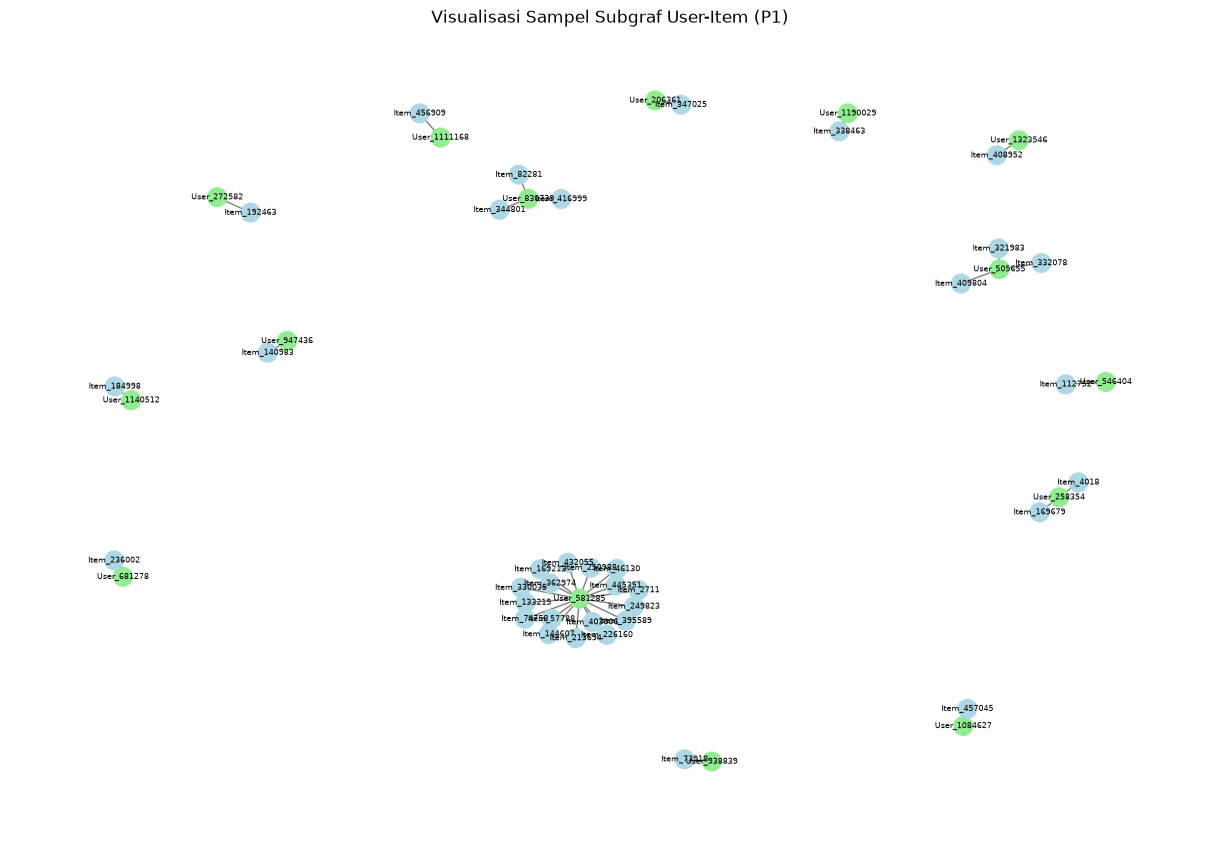

In [17]:
import networkx as nx
import matplotlib.pyplot as plt

# Mengambil 15 User pertama sebagai sampel visualisasi
sample_users = P1["visitorid"].drop_duplicates().head(15)
sample_data = P1[P1["visitorid"].isin(sample_users)]

G = nx.Graph()

for row in sample_data.itertuples():
    G.add_edge(
        f"User_{row.visitorid}",
        f"Item_{row.itemid}"
    )

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

node_colors = [
    "lightgreen" if node.startswith("User_") else "lightblue"
    for node in G.nodes()
]

nx.draw(
    G,
    pos,
    node_color=node_colors,
    node_size=180,
    font_size=6,
    with_labels=True,
    edge_color="gray"
)

plt.title("Visualisasi Sampel Subgraf User-Item (P1)")
plt.show()

In [18]:
# No. 2.1 (5) — Vector Space Modelling (VSM) terhadap Item
# Membentuk matriks Item-User dari transpose matriks User-Item
item_user = user_item.T.tocsr()

print("Shape matriks Item-User:", item_user.shape)
print("Jumlah pasangan Item-User unik:", item_user.nnz)
print("Jumlah dimensi setiap vektor Item:", item_user.shape[1])

Shape matriks Item-User: (76078, 153836)
Jumlah pasangan Item-User unik: 213066
Jumlah dimensi setiap vektor Item: 153836


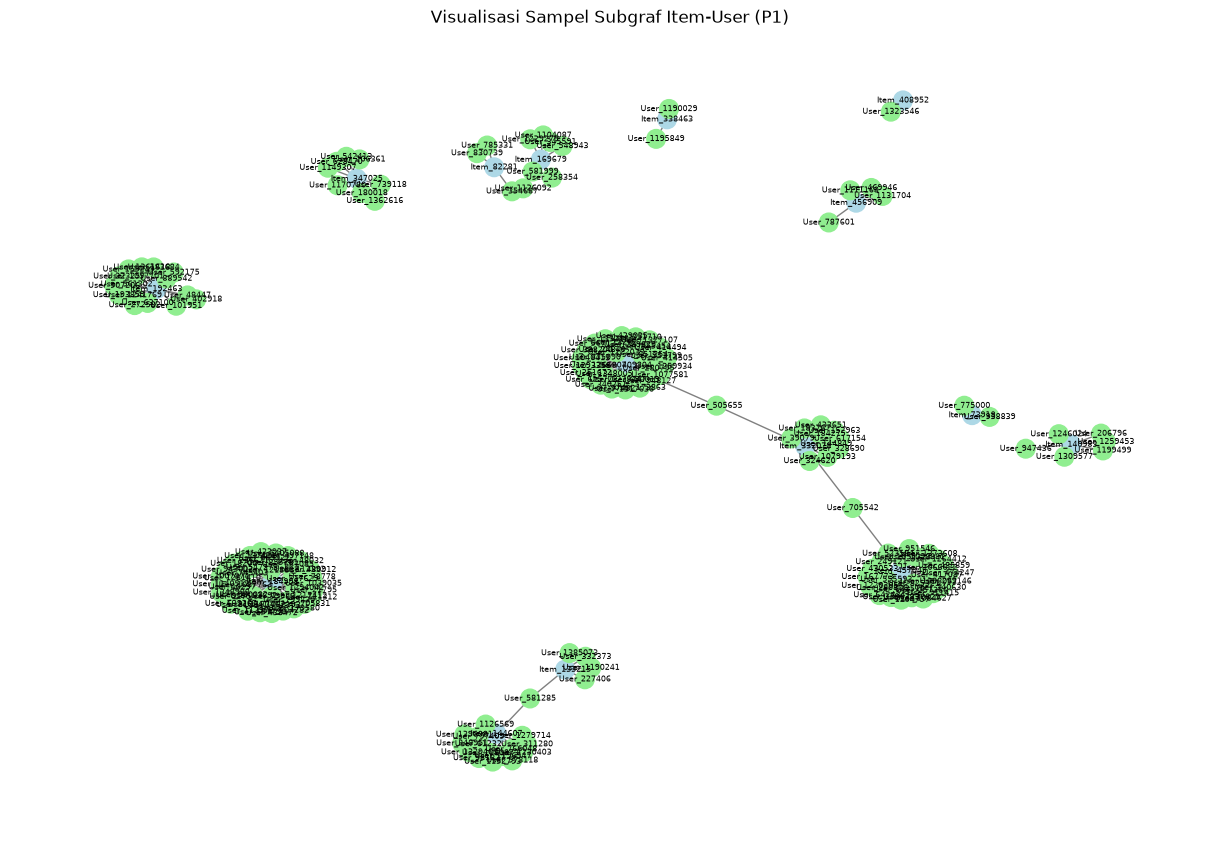

In [19]:
# Mengambil 15 Item pertama sebagai sampel visualisasi
sample_items = P1["itemid"].drop_duplicates().head(15)
sample_data_item = P1[P1["itemid"].isin(sample_items)]

G_item = nx.Graph()

for row in sample_data_item.itertuples():
    G_item.add_edge(
        f"Item_{row.itemid}",
        f"User_{row.visitorid}"
    )

plt.figure(figsize=(12, 8))

pos_item = nx.spring_layout(G_item, seed=42)

node_colors_item = [
    "lightblue" if node.startswith("Item_") else "lightgreen"
    for node in G_item.nodes()
]

nx.draw(
    G_item,
    pos_item,
    node_color=node_colors_item,
    node_size=180,
    font_size=6,
    with_labels=True,
    edge_color="gray"
)

plt.title("Visualisasi Sampel Subgraf Item-User (P1)")
plt.show()

In [20]:
# No. 2.1 (6) — Perbandingan Efisiensi Proyeksi User-Based dan Item-Based
# Menghitung jumlah kandidat pasangan similarity

n_user = user_item.shape[0]
n_item = item_user.shape[0]

pasangan_user = n_user * (n_user - 1) // 2
pasangan_item = n_item * (n_item - 1) // 2

print("=== Perbandingan Proyeksi ===")
print(f"Jumlah User: {n_user:,}")
print(f"Jumlah Item: {n_item:,}")

print(f"\nKandidat pasangan User-User: {pasangan_user:,}")
print(f"Kandidat pasangan Item-Item: {pasangan_item:,}")

print(f"\nRasio pasangan User terhadap Item: {pasangan_user / pasangan_item:.2f} kali")

=== Perbandingan Proyeksi ===
Jumlah User: 153,836
Jumlah Item: 76,078

Kandidat pasangan User-User: 11,832,680,530
Kandidat pasangan Item-Item: 2,893,893,003

Rasio pasangan User terhadap Item: 4.09 kali


**Kesimpulan Perbandingan Proyeksi**

Berdasarkan hasil VSM pada periode P1, proyeksi User-Based melibatkan 153.836 User, sedangkan Item-Based melibatkan 76.078 Item. Jumlah kandidat pasangan User–User mencapai 11.832.680.530, sementara kandidat pasangan Item–Item sebanyak 2.893.893.003.

Dengan demikian, jumlah kandidat pasangan pada User-Based sekitar 4,09 kali lebih besar dibandingkan Item-Based. Berdasarkan pertimbangan tersebut, proyeksi Item-Based dipilih untuk tahap perhitungan similarity karena memiliki ruang perbandingan yang lebih kecil. Pemilihan ini didasarkan pada efisiensi teoritis jumlah pasangan, bukan pengukuran waktu komputasi aktual.

In [21]:
# No. 2.1 (7) — Perhitungan Cosine Similarity Item-Based
# Memilih Item acuan berdasarkan jumlah User unik terbanyak

item_populer = (
    P1.groupby("itemid")["visitorid"]
    .nunique()
    .sort_values(ascending=False)
)

item_acuan = item_populer.index[0]

print("Item acuan:", item_acuan)
print("Jumlah User unik:", item_populer.iloc[0])


Item acuan: 187946
Jumlah User unik: 1317


In [22]:
#Menghitung Cosine Similarity 
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Mencari posisi Item acuan pada matriks
idx_acuan = np.where(item_ids == item_acuan)[0][0]

# Menghitung similarity Item acuan terhadap seluruh Item
similarity = cosine_similarity(
    item_user[idx_acuan],
    item_user
).flatten()

# Mengeluarkan Item acuan dari hasil rekomendasi
similarity[idx_acuan] = -1

In [23]:
# No. 7a — Menampilkan 5 similarity tertinggi dengan Cypher

data_7a = [
    {"itemid": int(item_ids[i]), "score": float(similarity[i])}
    for i in range(len(item_ids))
    if i != idx_acuan and similarity[i] > 0
]

query_7a = """
UNWIND $data AS row
RETURN $acuan AS item_acuan,
       row.itemid AS item_tujuan,
       row.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    records = session.run(
        query_7a,
        data=data_7a,
        acuan=int(item_acuan)
    )
    hasil_7a = pd.DataFrame([dict(r) for r in records])

display(hasil_7a)

,item_acuan,item_tujuan,similarity
0,187946,127784,0.074227
1,187946,22913,0.023689
2,187946,160665,0.023327
3,187946,38189,0.022334
4,187946,382128,0.022187


In [24]:
# No. 7b — Menyimpan 5 relasi SIMILAR_TO ke Neo4j

query_7b = """
MATCH (a:Item {itemid: $acuan})
MATCH (b:Item {itemid: $tujuan})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = $score
RETURN a.itemid AS item_acuan,
       b.itemid AS item_tujuan,
       r.score AS similarity
"""

hasil_7b = []

with driver.session(database="neo4j") as session:
    for row in hasil_7a.itertuples(index=False):
        record = session.run(
            query_7b,
            acuan=int(row.item_acuan),
            tujuan=int(row.item_tujuan),
            score=float(row.similarity)
        ).single()

        if record is not None:
            hasil_7b.append(dict(record))

display(pd.DataFrame(hasil_7b))

,item_acuan,item_tujuan,similarity
0,187946,127784,0.074227
1,187946,22913,0.023689
2,187946,160665,0.023327
3,187946,38189,0.022334
4,187946,382128,0.022187


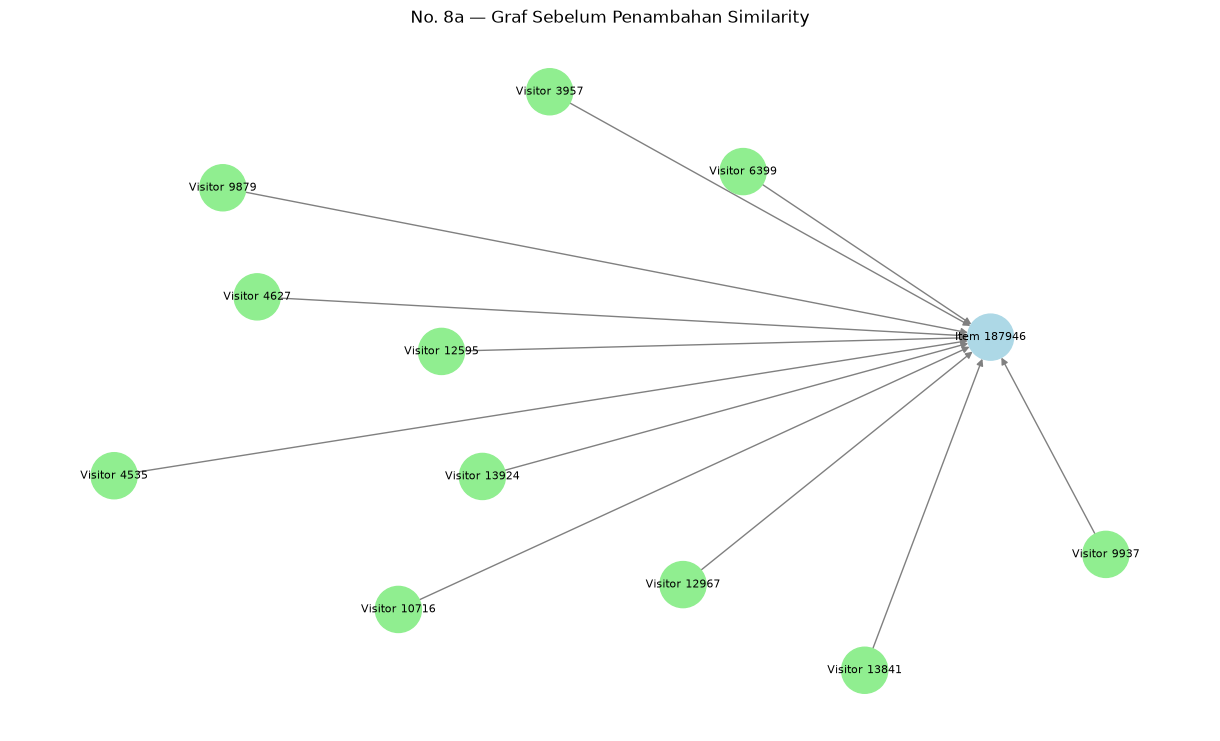

In [25]:
# No. 8a — Graf sebelum penambahan similarity

query_8a = """
MATCH (u:Visitor)-[r]->(a:Item {itemid: $acuan})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
  AND r.timestamp >= 1438387200000
  AND r.timestamp < 1439683200000
RETURN u.visitorid AS visitor,
       a.itemid AS item,
       type(r) AS interaksi
ORDER BY u.visitorid, type(r)
LIMIT 15
"""

with driver.session(database="neo4j") as session:
    records = session.run(query_8a, acuan=int(item_acuan))
    data_8a = [dict(r) for r in records]

G_awal = nx.DiGraph()

for row in data_8a:
    G_awal.add_edge(
        f"Visitor {row['visitor']}",
        f"Item {row['item']}",
        relation=row["interaksi"]
    )

pos_awal = nx.spring_layout(G_awal, seed=42)

plt.figure(figsize=(12, 7))

warna = [
    "lightgreen" if n.startswith("Visitor") else "lightblue"
    for n in G_awal.nodes()
]

nx.draw(
    G_awal, pos_awal,
    with_labels=True,
    node_color=warna,
    node_size=1100,
    font_size=8,
    edge_color="gray",
    arrows=True
)

plt.title("No. 8a — Graf Sebelum Penambahan Similarity")
plt.show()

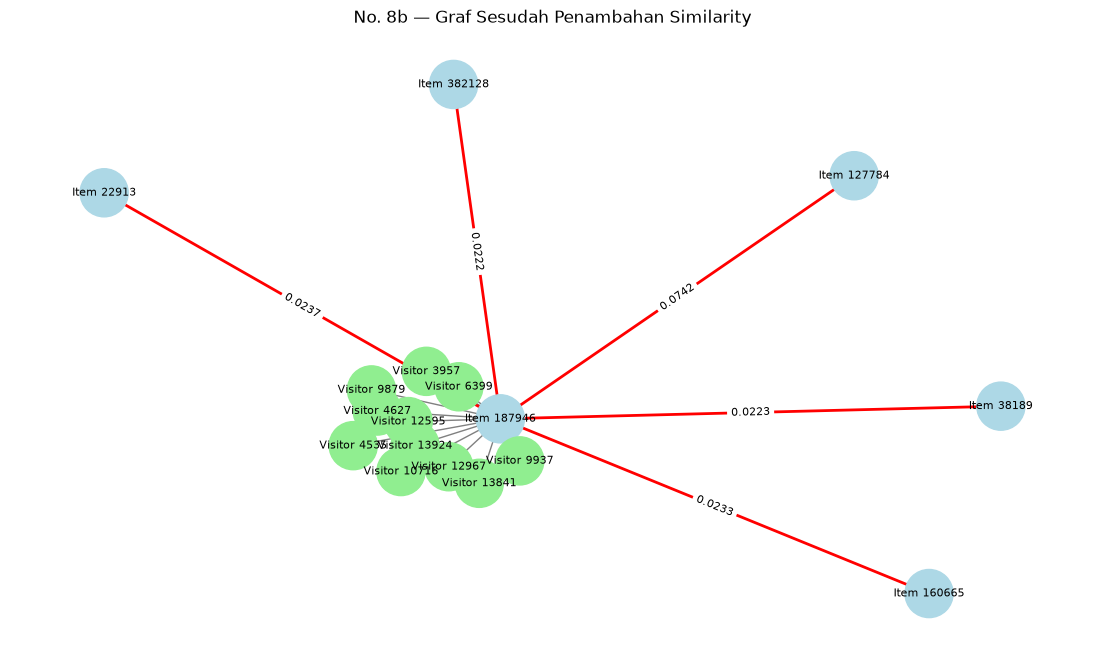

In [27]:
# No. 8b — Graf sesudah penambahan similarity

G_sesudah = G_awal.copy()

for row in hasil_7b:
    G_sesudah.add_edge(
        f"Item {row['item_acuan']}",
        f"Item {row['item_tujuan']}",
        relation="SIMILAR_TO",
        score=row["similarity"]
    )

pos_sesudah = nx.spring_layout(
    G_sesudah,
    pos=pos_awal,
    fixed=list(G_awal.nodes()),
    seed=42
)

plt.figure(figsize=(14, 8))

warna = [
    "lightgreen" if n.startswith("Visitor") else "lightblue"
    for n in G_sesudah.nodes()
]

nx.draw_networkx_nodes(
    G_sesudah, pos_sesudah,
    node_color=warna,
    node_size=1200
)

nx.draw_networkx_labels(
    G_sesudah, pos_sesudah,
    font_size=8
)

edge_awal = [
    (u, v) for u, v, d in G_sesudah.edges(data=True)
    if d["relation"] != "SIMILAR_TO"
]

edge_similarity = [
    (u, v) for u, v, d in G_sesudah.edges(data=True)
    if d["relation"] == "SIMILAR_TO"
]

nx.draw_networkx_edges(
    G_sesudah, pos_sesudah,
    edgelist=edge_awal,
    edge_color="gray",
    arrows=True
)

nx.draw_networkx_edges(
    G_sesudah, pos_sesudah,
    edgelist=edge_similarity,
    edge_color="red",
    width=2,
    arrows=True
)

label_similarity = {
    (u, v): f"{d['score']:.4f}"
    for u, v, d in G_sesudah.edges(data=True)
    if d["relation"] == "SIMILAR_TO"
}

nx.draw_networkx_edge_labels(
    G_sesudah, pos_sesudah,
    edge_labels=label_similarity,
    font_size=8
)

plt.title("No. 8b — Graf Sesudah Penambahan Similarity")
plt.axis("off")
plt.show()

### 2.2 Analytics

Kandidat awal merupakan User dengan minimal lima Item unik pada P1 dan tiga Item unik pada P2. Selanjutnya, kandidat diperiksa berdasarkan ketersediaan lima tetangga dengan similarity positif dan minimal tiga Item baru yang dapat direkomendasikan berdasarkan P1.

Kriteria tersebut digunakan untuk memastikan User terpilih memiliki data yang cukup untuk menjalankan KNN dan menghasilkan tiga rekomendasi.

In [18]:
# No. 2.2 (1) — Pemilihan User acak dengan seed 169

jumlah_p1 = P1.groupby("visitorid")["itemid"].nunique()
jumlah_p2 = P2.groupby("visitorid")["itemid"].nunique()

kandidat_awal = sorted(
    set(jumlah_p1[jumlah_p1 >= 5].index) &
    set(jumlah_p2[jumlah_p2 >= 3].index)
)

kandidat_valid = []

for uid in kandidat_awal:
    idx = np.where(user_ids == uid)[0][0]

    sim = cosine_similarity(
        user_item[idx],
        user_item
    ).flatten()

    sim[idx] = -1

    tetangga_idx = np.where(sim > 0)[0]
    tetangga_idx = tetangga_idx[
        np.argsort(-sim[tetangga_idx], kind="stable")
    ][:5]

    if len(tetangga_idx) < 5:
        continue

    item_target = set(
        P1.loc[P1["visitorid"] == uid, "itemid"]
    )

    item_tetangga = set(
        P1.loc[
            P1["visitorid"].isin(user_ids[tetangga_idx]),
            "itemid"
        ]
    )

    if len(item_tetangga - item_target) >= 3:
        kandidat_valid.append(int(uid))

# Pengacakan dilakukan setelah seluruh kriteria diperiksa
rng = np.random.default_rng(169)
user_terpilih = int(rng.choice(sorted(kandidat_valid)))

print("Kandidat awal:", len(kandidat_awal))
print("Kandidat valid:", len(kandidat_valid))
print("User terpilih:", user_terpilih)
print("Item unik P1:", jumlah_p1[user_terpilih])
print("Item unik P2:", jumlah_p2[user_terpilih])

Kandidat awal: 317
Kandidat valid: 94
User terpilih: 1246166
Item unik P1: 7
Item unik P2: 6


In [19]:
# No. 2.2 (1a) — Fungsi rekomendasi User-Based KNN

def rekomendasi_knn(user_target, k, n_rekomendasi):
    # Menghitung similarity User
    idx_user = np.where(user_ids == user_target)[0][0]

    sim_user = cosine_similarity(
        user_item[idx_user],
        user_item
    ).flatten()

    sim_user[idx_user] = -1

    # Memilih k tetangga dengan similarity positif
    idx_tetangga = np.where(sim_user > 0)[0]
    idx_tetangga = idx_tetangga[
        np.argsort(-sim_user[idx_tetangga], kind="stable")
    ][:k]

    tetangga = pd.DataFrame({
        "visitorid": user_ids[idx_tetangga],
        "similarity": sim_user[idx_tetangga]
    })

    # Mengambil interaksi tetangga dari P1
    interaksi = P1[
        P1["visitorid"].isin(tetangga["visitorid"])
    ][["visitorid", "itemid"]].drop_duplicates()

    kandidat = interaksi.merge(tetangga, on="visitorid")

    # Mengecualikan Item yang sudah diakses User target
    item_sudah = set(
        P1.loc[P1["visitorid"] == user_target, "itemid"]
    )

    kandidat = kandidat[
        ~kandidat["itemid"].isin(item_sudah)
    ]

    # Menghitung skor dan mengurutkan rekomendasi
    rekomendasi = (
        kandidat.groupby("itemid", as_index=False)
        .agg(
            skor=("similarity", "sum"),
            jumlah_tetangga=("visitorid", "nunique")
        )
        .sort_values(
            ["skor", "jumlah_tetangga", "itemid"],
            ascending=[False, False, True]
        )
        .head(n_rekomendasi)
        .reset_index(drop=True)
    )

    return tetangga, rekomendasi

# Memastikan fungsi rekomendasi KNN berhasil dibuat
print("Fungsi rekomendasi_knn berhasil dibuat.")
print("User yang akan dianalisis:", user_terpilih)
print("Parameter k dan jumlah rekomendasi ditentukan pada No. 1b.")

Fungsi rekomendasi_knn berhasil dibuat.
User yang akan dianalisis: 1246166
Parameter k dan jumlah rekomendasi ditentukan pada No. 1b.


In [ ]:
# No. 2.2 (1b) — Rekomendasi 3 Item dengan k = 5
#Parameter k = 5 digunakan untuk memilih lima User dengan nilai similarity tertinggi. 
# Berdasarkan interaksi kelima tetangga tersebut, sistem menghasilkan tiga Item rekomendasi untuk User terpilih.

hasil_knn, hasil_rekomendasi = rekomendasi_knn(
    user_target=user_terpilih,
    k=5,
    n_rekomendasi=3
)

print("User terpilih:", user_terpilih)

print("\n5 Tetangga Terdekat:")
display(hasil_knn)

print("\n3 Item Rekomendasi:")
display(hasil_rekomendasi)

User terpilih: 1246166

5 Tetangga Terdekat:


,visitorid,similarity
0,1321193,0.636146
1,446675,0.588348
2,354499,0.585369
3,925847,0.554700
4,1069776,0.554700



3 Item Rekomendasi:


,itemid,skor,jumlah_tetangga
0,256706,1.221516,2
1,128745,0.585369,1
2,162139,0.585369,1


In [ ]:
# No. 2.2 (2a) — Menghitung Hit@5
# Hit@5 bernilai 1 apabila terdapat minimal satu Item rekomendasi 
# yang sesuai dengan Item aktual pada P2, dan bernilai 0 apabila tidak ditemukan kecocokan.


item_aktual = set(
    P2.loc[P2["visitorid"] == user_terpilih, "itemid"]
)

item_prediksi = hasil_rekomendasi["itemid"].head(5).tolist()

item_hit = set(item_prediksi) & item_aktual
hit_5 = int(len(item_hit) > 0)

print("Item aktual P2:", sorted(item_aktual))
print("Item rekomendasi:", item_prediksi)
print("Item yang cocok:", sorted(item_hit))
print("Hit@5:", hit_5)

Item aktual P2: [66933, 183176, 256706, 271887, 405862, 457814]
Item rekomendasi: [256706, 128745, 162139]
Item yang cocok: [256706]
Hit@5: 1


In [ ]:
# No. 2.2 (2b) — NDCG@5
# NDCG@5 mengevaluasi kualitas urutan rekomendasi berdasarkan posisi Item relevan. 
# Relevansi ditentukan secara biner dengan membandingkan Item rekomendasi terhadap Item aktual pada P2.
# Karena daftar rekomendasi hanya berisi tiga Item sesuai permintaan No. 1b, dua posisi sisanya dianggap tidak terisi.

relevansi = [
    int(item in item_aktual)
    for item in item_prediksi[:5]
]

dcg_5 = sum(
    rel / np.log2(i + 2)
    for i, rel in enumerate(relevansi)
)

ideal_count = min(5, len(item_aktual))
idcg_5 = sum(
    1 / np.log2(i + 2)
    for i in range(ideal_count)
)

ndcg_5 = dcg_5 / idcg_5 if idcg_5 > 0 else 0.0

print("Relevansi:", relevansi)
print("DCG@5:", round(dcg_5, 6))
print("IDCG@5:", round(idcg_5, 6))
print("NDCG@5:", round(ndcg_5, 6))

Relevansi: [1, 0, 0]
DCG@5: 1.0
IDCG@5: 2.948459
NDCG@5: 0.33916


## Ringkasan Hasil

Pengerjaan menggunakan dua periode data RetailRocket, yaitu P1 sebagai data training dan P2 sebagai data testing.

Berdasarkan perbandingan jumlah kandidat pasangan, proyeksi Item-Based dipilih untuk analisis similarity. Sementara itu, implementasi User-Based KNN dengan seed 169 menghasilkan User terpilih 1246166 dan tiga rekomendasi, yaitu Item 256706, 128745, dan 162139.

Evaluasi menunjukkan bahwa Item 256706 sesuai dengan interaksi aktual pada P2, sehingga diperoleh Hit@5 sebesar 1 dan NDCG@5 sebesar 0,3392.

Pembahasan lebih lengkap disajikan dalam Laporan_UTS_GSD.